In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

data = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))


In [3]:
groups = ["comp.graphics", "sci.space", "rec.autos", "rec.sport.hockey",
          "talk.politics.guns", "talk.politics.mideast",
          "soc.religion.christian", "alt.atheism"]
data = fetch_20newsgroups(subset="train", categories=groups,
                          remove=("headers", "footers", "quotes"))
posts = data.data
true_labels = [data.target_names[i] for i in data.target]

In [4]:
vectorizer = TfidfVectorizer(stop_words="english", min_df=5, max_df=0.5)
X = vectorizer.fit_transform(posts)

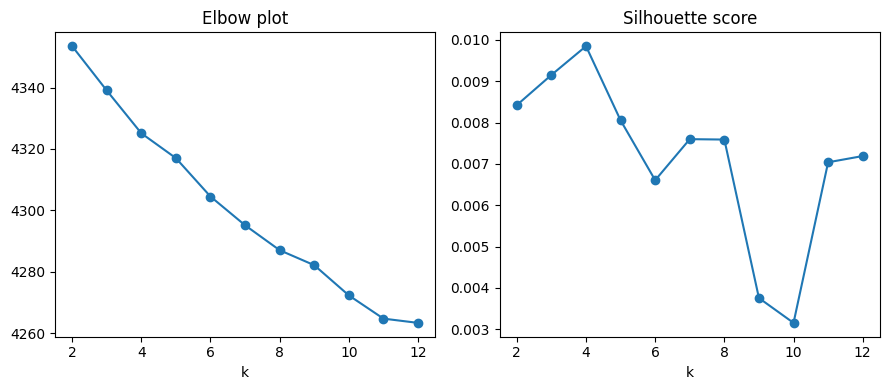

In [5]:
k_values = range(2, 13)
inertias, scores = [], []
for k in k_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertias.append(model.inertia_)
    scores.append(silhouette_score(X, model.labels_))

plt.figure(figsize=(9, 4))
plt.subplot(1, 2, 1)
plt.plot(k_values, inertias, "o-")
plt.title("Elbow plot")
plt.xlabel("k")
plt.subplot(1, 2, 2)
plt.plot(k_values, scores, "o-")
plt.title("Silhouette score")
plt.xlabel("k")
plt.tight_layout()
plt.savefig("k_selection.png")

In [6]:
K = 8
model = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X)

In [7]:
words = vectorizer.get_feature_names_out()
for c in range(K):
    members = [i for i in range(len(posts)) if model.labels_[i] == c]
    top_words = words[np.argsort(model.cluster_centers_[c])[::-1][:8]]
    print(f"\nCluster {c} ({len(members)} posts)")
    print("Top words:", ", ".join(top_words))
    for i in members[:2]:
        print("  Example:", " ".join(posts[i].split())[:150])



Cluster 0 (1984 posts)
Top words: just, space, like, don, think, know, time, nasa
  Example: Sorry folks, I should have done this, and meant to just after i hit the send key... Orbital Elements of Comet 1977VII (from Dance files) p(au) 3.42434
  Example: 

Cluster 1 (118 posts)
Top words: armenian, armenians, turkish, armenia, turks, turkey, people, genocide
  Example: That's why zoologists refer to you as a 'fecal shield'. Colonel Semen M. Budienny, a subsequent Soviet military fame, said about the Armenian genocide
  Example: Nobody ever exposed your crimes like that before? What was your personal role in the murder of Orhan Gunduz and Kemal Arikan, again? How many more Mus

Cluster 2 (469 posts)
Top words: thanks, graphics, files, file, program, image, know, hi
  Example: If you are looking for viewer try VPIC60
  Example: : I've been trying to view .tga files created in POVRAY. I have the Diamond : SpeedStar 24 Video board (not the _24X_). So far I can convert them to :

Cluster 3

In [8]:
table = pd.crosstab(pd.Series(true_labels, name="newsgroup"),
                    pd.Series(model.labels_, name="cluster"))
print("\n", table)
table.to_csv("newsgroup_vs_cluster.csv")



 cluster                   0    1    2    3    4    5    6    7
newsgroup                                                     
alt.atheism             188    0    3    4   20  208    0   57
comp.graphics           199    0  383    0    0    2    0    0
rec.autos               261    0   20  293    9   11    0    0
rec.sport.hockey        170    0   12    1    0    7  410    0
sci.space               544    0   34    1    5    7    1    1
soc.religion.christian  136    0   14    0    7  269    0  173
talk.politics.guns      278    0    2    2  248   16    0    0
talk.politics.mideast   208  118    1    0  210   25    0    2
